## 1. Выбор данных и описание

Датасет: **UCI Student Performance (Portuguese language, `student-por.csv`)** — 649 объектов, 33 признака, пропусков нет.

**Объект** — учащийся португальской школы; для каждого известны демография, семейный контекст, учебные привычки и итоговая оценка `G3`.

Выбраны 8 переменных:
- `sex` — пол (F/M);
- `address` — тип жилья (R — сельская местность, U — город);
- `Medu` — образование матери (0–4 → low/medium/high);
- `studytime` — недельное учебное время (1–4);
- `failures` — число прошлых провалов (0, 1, 2, 3+);
- `higher` — хочет ли получать высшее образование (no/yes);
- `absences` — число пропусков (дискретизировано);
- `G3` — итоговая оценка (дискретизирована).

**Содержательные гипотезы о зависимостях:** демография и образование матери влияют на учебные привычки; привычки и мотивация влияют на прошлые провалы и посещаемость; провалы, пропуски и учебное время определяют итоговую оценку. Эти гипотезы и лягут в основу графа.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("student-por.csv", sep=";")

print("Размер:", df.shape)
print("\nПропуски:", df.isna().sum().sum())
print("\nТипы:\n", df.dtypes.value_counts())

cols = ["sex", "address", "Medu", "studytime", "failures",
        "higher", "absences", "G3"]
data = df[cols].copy()

print("\n--- Распределения ---")
for c in cols:
    print(f"\n{c}:")
    print(data[c].value_counts(dropna=False).sort_index())

Размер: (649, 33)

Пропуски: 0

Типы:
 str      17
int64    16
Name: count, dtype: int64

--- Распределения ---

sex:
sex
F    383
M    266
Name: count, dtype: int64

address:
address
R    197
U    452
Name: count, dtype: int64

Medu:
Medu
0      6
1    143
2    186
3    139
4    175
Name: count, dtype: int64

studytime:
studytime
1    212
2    305
3     97
4     35
Name: count, dtype: int64

failures:
failures
0    549
1     70
2     16
3     14
Name: count, dtype: int64

higher:
higher
no      69
yes    580
Name: count, dtype: int64

absences:
absences
0     244
1      12
2     110
3       7
4      93
5      12
6      49
7       3
8      42
9       7
10     21
11      5
12     12
13      1
14      8
15      2
16     10
18      3
21      2
22      2
24      1
26      1
30      1
32      1
Name: count, dtype: int64

G3:
G3
0      15
1       1
5       1
6       3
7      10
8      35
9      35
10     97
11    104
12     72
13     82
14     63
15     49
16     36
17     29
18     15
19   

## 2. Подготовка данных и дискретизация

Пропусков нет, все категории наполнены. Непрерывные/многозначные признаки приведены к категориям:

- **`absences`** → `none` (0), `low` (1–5), `high` (6+). Распределение сильно скошено вправо (244 нуля, хвост до 32); порог 6 соответствует верхнему квартилю и «провалу» в частотах после 5.
- **`G3`** → `fail` (0–9), `pass` (10–13), `high` (14–19). Порог 10 — официальный проходной балл; порог 14 даёт примерно сбалансированное разбиение верхней части.
- **`Medu`** → `low` (0–1), `medium` (2), `high` (3–4). Объединение 0 и 1 убирает редкую категорию (6 наблюдений).
- **`failures`** → `0`, `1`, `2`, `3+` — редкие значения 3+ (14 наблюдений) объединены.

Итог: у каждой переменной 2–4 состояния, все ячейки наполнены, чего достаточно для устойчивой оценки CPT.

In [2]:
data_disc = data.copy()

data_disc["absences"] = pd.cut(
    data_disc["absences"],
    bins=[-1, 0, 5, np.inf],
    labels=["none", "low", "high"]
).astype(str)

data_disc["G3"] = pd.cut(
    data_disc["G3"],
    bins=[-1, 9, 13, np.inf],
    labels=["fail", "pass", "high"]
).astype(str)

data_disc["Medu"] = pd.cut(
    data_disc["Medu"],
    bins=[-1, 1, 2, 4],
    labels=["low", "medium", "high"]
).astype(str)

data_disc["failures"] = data_disc["failures"].apply(
    lambda x: "3+" if x >= 3 else str(x)
)

for c in ["studytime", "sex", "address", "higher"]:
    data_disc[c] = data_disc[c].astype(str)

print("--- После дискретизации ---")
for c in data_disc.columns:
    print(f"\n{c}:")
    print(data_disc[c].value_counts().sort_index())

print("\nВсего строк:", len(data_disc))

--- После дискретизации ---

sex:
sex
F    383
M    266
Name: count, dtype: int64

address:
address
R    197
U    452
Name: count, dtype: int64

Medu:
Medu
high      314
low       149
medium    186
Name: count, dtype: int64

studytime:
studytime
1    212
2    305
3     97
4     35
Name: count, dtype: int64

failures:
failures
0     549
1      70
2      16
3+     14
Name: count, dtype: int64

higher:
higher
no      69
yes    580
Name: count, dtype: int64

absences:
absences
high    171
low     234
none    244
Name: count, dtype: int64

G3:
G3
fail    100
high    194
pass    355
Name: count, dtype: int64

Всего строк: 649


## 3. Постановка вопросов

1. **Как образование матери влияет на итоговую оценку?** `P(G3=high)` vs `P(G3=high | Medu=high)`.
2. **Как прошлые провалы и пропуски вместе меняют риск провала?** `P(G3=fail)` vs `P(G3=fail | failures=0, absences=none)`.
3. **Компенсирует ли мотивация на вуз малое время учёбы?** `P(G3 | studytime=1)` vs `P(G3 | higher=yes, studytime=1)`.


## 4. Структура графа

Предлагается DAG из 8 узлов и 10 рёбер. Направления отражают временной/логический порядок: демография и семья → привычки и установки → поведение → результат.

| Ребро | Почему зависимость | Почему такое направление |
|---|---|---|
| `sex → studytime` | девушки в среднем учатся больше | пол дан от рождения, учёба — поведение |
| `Medu → studytime` | образованная мать организует режим учёбы | образование матери — фоновый фактор |
| `Medu → higher` | образование матери формирует установку на вуз | установка складывается в семье |
| `address → absences` | сельским детям дальше добираться | место жительства — фиксированный фон |
| `studytime → absences` | кто больше учится, реже пропускает | привычка → посещаемость |
| `studytime → failures` | больше подготовки → меньше провалов | привычка предшествует результату |
| `higher → failures` | мотивация на вуз снижает риск провала | установка → учебное поведение |
| `failures → G3` | прошлые провалы предсказывают итог | прошлое → настоящее |
| `absences → G3` | пропуски снижают итоговую оценку | посещаемость влияет на результат |
| `studytime → G3` | время учёбы напрямую влияет на оценку | привычка → результат |

Позиции узлов на рисунке сгруппированы по смыслу: слева — фоновые характеристики (пол, образование матери, тип жилья, установка на вуз), в центре — учебные привычки (`studytime`), справа — поведение (`absences`, `failures`) и результат (`G3`).

Прямые рёбра `sex → G3`, `address → G3` не добавлены: их влияние предположительно опосредовано, а ребро «по корреляции» ТЗ запрещает.

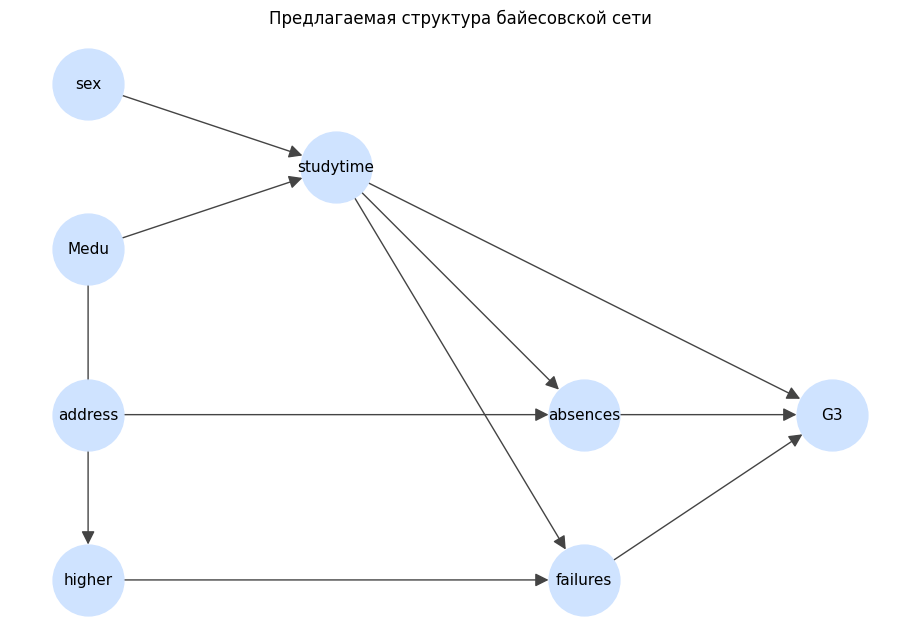

In [3]:
import networkx as nx
import matplotlib.pyplot as plt

edges = [
    ("sex", "studytime"),
    ("Medu", "studytime"),
    ("Medu", "higher"),
    ("address", "absences"),
    ("studytime", "absences"),
    ("studytime", "failures"),
    ("higher", "failures"),
    ("failures", "G3"),
    ("absences", "G3"),
    ("studytime", "G3"),
]

G = nx.DiGraph()
G.add_edges_from(edges)

pos = {
    "sex": (0, 3), "Medu": (0, 2), "address": (0, 1), "higher": (0, 0),
    "studytime": (1, 2.5),
    "absences": (2, 1),
    "failures": (2, 0),
    "G3": (3, 1),
}

plt.figure(figsize=(9, 6))
nx.draw(G, pos, with_labels=True, node_size=2600, node_color="#cfe3ff",
        font_size=11, arrows=True, arrowsize=20, edge_color="#444")
plt.title("Предлагаемая структура байесовской сети")
plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
plt.show()

## 5. Оценка параметров сети

Параметры оцениваются методом Байеса с prior `BDeu` и `equivalent_sample_size=1` (лапласово сглаживание). Это защищает от нулевых вероятностей в редких ячейках (`failures=3+`, `studytime=4`). CPT для `G3`, `studytime` и `failures` выводятся в читаемом виде с проверкой: сумма вероятностей по каждой строке должна быть равна 1.

In [4]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator

edges = [
    ("sex", "studytime"),
    ("Medu", "studytime"),
    ("Medu", "higher"),
    ("address", "absences"),
    ("studytime", "absences"),
    ("studytime", "failures"),
    ("higher", "failures"),
    ("failures", "G3"),
    ("absences", "G3"),
    ("studytime", "G3"),
]

model = DiscreteBayesianNetwork(edges)

state_names = {
    "sex": ["F", "M"],
    "address": ["R", "U"],
    "Medu": ["low", "medium", "high"],
    "studytime": ["1", "2", "3", "4"],
    "failures": ["0", "1", "2", "3+"],
    "higher": ["no", "yes"],
    "absences": ["none", "low", "high"],
    "G3": ["fail", "pass", "high"],
}

estimator = DiscreteBayesianEstimator(
    prior_type="BDeu",
    equivalent_sample_size=1,
    state_names=state_names,
)

model.fit(data_disc, estimator=estimator)

import networkx as nx
print("Модель построена. Узлов:", len(model.nodes()))
print("Рёбер:", len(model.edges()))
print("Граф ацикличен:", nx.is_directed_acyclic_graph(model))

Модель построена. Узлов: 8
Рёбер: 10
Граф ацикличен: True


In [5]:
import pandas as pd

def show_cpd(model, var):
    cpd = model.get_cpds(var)
    df = cpd.to_dataframe()
    
    row_sums = df.sum(axis=1)
    print(f"\n===== CPT: {var} =====")
    print(f"Проверка сумм по строкам (min={row_sums.min():.3f}, max={row_sums.max():.3f})")
    
    with pd.option_context("display.max_rows", 80, "display.width", 200):
        print(df.round(3))

show_cpd(model, "G3")
show_cpd(model, "studytime")
show_cpd(model, "failures")


===== CPT: G3 =====
Проверка сумм по строкам (min=1.000, max=1.000)
G3                            fail   high   pass
absences failures studytime                     
high     0        1          0.196  0.216  0.588
                  2          0.113  0.339  0.548
                  3          0.001  0.417  0.583
                  4          0.001  0.444  0.555
         1        1          0.385  0.077  0.538
                  2          0.417  0.001  0.583
                  3          0.993  0.003  0.003
                  4          0.333  0.333  0.333
         2        1          0.333  0.333  0.333
                  2          0.664  0.002  0.333
                  3          0.007  0.007  0.986
                  4          0.333  0.333  0.333
         3+       1          0.499  0.002  0.499
                  2          0.498  0.003  0.498
                  3          0.333  0.333  0.333
                  4          0.333  0.333  0.333
low      0        1          0.097  0.210  0.693


### Интерпретация CPT

- **`studytime`**: при `Medu=high` у девушек наиболее вероятная категория — `studytime=2` (`P=0.521`), у юношей — `studytime=1` (`P=0.408`). Связь `sex → studytime` есть, но не монотонная: в крайних категориях (1 и 4) различия между полами не так выражены.
- **`failures`**: при `higher=yes` вероятность «ноль провалов» резко выше почти на всех уровнях `studytime` (0.839–0.937 против 0.492–0.956 при `no`). Эффект `higher` сильнее эффекта `studytime` самого по себе.
- **`G3`**: при `failures=0, absences=none` рост `studytime` 1→3 повышает `P(high)` с 0.220 до 0.561 и снижает `P(fail)` с 0.160 до 0.025. При `absences=high` те же значения ниже (0.216 → 0.417) — пропуски «съедают» часть эффекта. В ячейках `failures=2, 3+` часто ровно `1/3` — следствие сглаживания при малом числе наблюдений; это ограничение модели.

## 6. Вероятностный вывод

Для каждого вопроса сравниваем prior и posterior (алгоритм `VariableElimination`).

| Вопрос | Величина | Prior | Posterior | Δ |
|---|---|---|---|---|
| Q1: `Medu=high` | `P(G3=high)` | 0.296 | 0.313 | +1.7 п.п. |
| Q2: `failures=0, absences=none` | `P(G3=fail)` | 0.150 | 0.090 | −6.0 п.п. |
| Q3: `higher=yes` при `studytime=1` | `P(G3=fail)` | 0.220 | 0.206 | −1.4 п.п. |

**Интерпретация:**
- **Q1** — слабый сдвиг: `Medu` не прямой родитель `G3`, влияние идёт через `studytime` и `higher`.
- **Q2** — самый сильный эффект: `failures` и `absences` — прямые родители `G3`, evidence бьёт точно в CPT цели.
- **Q3** — почти нулевой эффект: `higher` влияет на `G3` только через `failures`, а при фиксированном `studytime=1` этот путь слаб. Мотивация не компенсирует малое время учёбы в рамках данной структуры.

Сила эффекта убывает по мере удаления evidence от целевой переменной в графе: Q2 ≫ Q1 > Q3.

In [6]:
import warnings
warnings.filterwarnings("ignore", message=".*StructureScore.*")
from pgmpy.inference import VariableElimination

infer = VariableElimination(model)

prior_g3 = infer.query(["G3"], show_progress=False)
print("Prior P(G3):\n", prior_g3)

q1_post = infer.query(["G3"], evidence={"Medu": "high"}, show_progress=False)
print("\nQ1: влияние Medu на G3")
print("P(G3 | Medu=high):\n", q1_post)

q2_post = infer.query(["G3"], evidence={"failures": "0", "absences": "none"}, show_progress=False)
print("\nQ2: провалы + пропуски → риск fail")
print("P(G3 | failures=0, absences=none):\n", q2_post)

q3_base = infer.query(["G3"], evidence={"studytime": "1"}, show_progress=False)
q3_post = infer.query(["G3"], evidence={"higher": "yes", "studytime": "1"}, show_progress=False)
print("\nQ3: higher=yes при studytime=1")
print("P(G3 | studytime=1):\n", q3_base)
print("\nP(G3 | higher=yes, studytime=1):\n", q3_post)

Prior P(G3):
 +----------+-----------+
| G3       |   phi(G3) |
+==========+===========+
| G3(fail) |    0.1505 |
+----------+-----------+
| G3(pass) |    0.5536 |
+----------+-----------+
| G3(high) |    0.2959 |
+----------+-----------+

Q1: влияние Medu на G3
P(G3 | Medu=high):
 +----------+-----------+
| G3       |   phi(G3) |
+==========+===========+
| G3(fail) |    0.1373 |
+----------+-----------+
| G3(pass) |    0.5499 |
+----------+-----------+
| G3(high) |    0.3128 |
+----------+-----------+

Q2: провалы + пропуски → риск fail
P(G3 | failures=0, absences=none):
 +----------+-----------+
| G3       |   phi(G3) |
+==========+===========+
| G3(fail) |    0.0899 |
+----------+-----------+
| G3(pass) |    0.5189 |
+----------+-----------+
| G3(high) |    0.3913 |
+----------+-----------+

Q3: higher=yes при studytime=1
P(G3 | studytime=1):
 +----------+-----------+
| G3       |   phi(G3) |
+==========+===========+
| G3(fail) |    0.2195 |
+----------+-----------+
| G3(pass) |    

## 7. Эксперимент с evidence

Выбираем целевую переменную `G3` и последовательно добавляем информацию о других переменных. Цель — показать, как модель реагирует на новую информацию и как эта реакция объясняется структурой графа.

Последовательность шагов:
1. ничего не известно (prior);
2. известно `failures = 0`;
3. известно `failures = 0`, `absences = none`;
4. добавлено `studytime = 3`;
5. добавлено `higher = yes`;
6. добавлено `Medu = high`.

Шаги 2–4 добавляют **прямых родителей** `G3`, поэтому ожидается заметный сдвиг. Шаги 5–6 добавляют переменные, которые **не являются прямыми родителями** `G3`: они влияют на неё только опосредованно, через уже зафиксированные `failures` / `studytime`. Поэтому здесь ожидается «плато» — почти нулевое изменение распределения.

In [7]:
import pandas as pd

evidence_steps = [
    ("ничего не известно", {}),
    ("failures = 0", {"failures": "0"}),
    ("failures = 0, absences = none", {"failures": "0", "absences": "none"}),
    ("failures = 0, absences = none, studytime = 3",
     {"failures": "0", "absences": "none", "studytime": "3"}),
    ("failures = 0, absences = none, studytime = 3, higher = yes",
     {"failures": "0", "absences": "none", "studytime": "3", "higher": "yes"}),
    ("+ Medu = high",
     {"failures": "0", "absences": "none", "studytime": "3", "higher": "yes", "Medu": "high"}),
]

rows = []
for label, ev in evidence_steps:
    q = infer.query(["G3"], evidence=ev, show_progress=False)
    probs = q.values
    rows.append({"evidence": label, "P(fail)": probs[0], "P(pass)": probs[1], "P(high)": probs[2]})

result = pd.DataFrame(rows).set_index("evidence")
pd.set_option("display.max_colwidth", None)
print(result.round(3))

                                                            P(fail)  P(pass)  \
evidence                                                                       
ничего не известно                                            0.151    0.554   
failures = 0                                                  0.095    0.559   
failures = 0, absences = none                                 0.090    0.519   
failures = 0, absences = none, studytime = 3                  0.025    0.415   
failures = 0, absences = none, studytime = 3, higher = yes    0.025    0.415   
+ Medu = high                                                 0.025    0.415   

                                                            P(high)  
evidence                                                             
ничего не известно                                            0.296  
failures = 0                                                  0.346  
failures = 0, absences = none                                 0.391  
failures 

### Визуализация изменения распределения

Столбчатая диаграмма наглядно показывает, на каких шагах распределение `G3` сдвигается, а на каких остаётся практически неизменным.

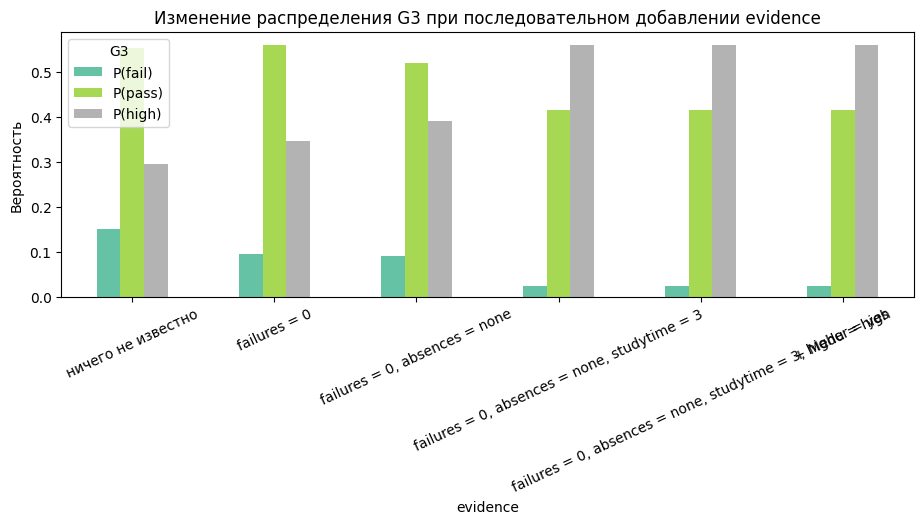

In [8]:
import matplotlib.pyplot as plt

ax = result.plot(kind="bar", figsize=(11, 5), colormap="Set2", rot=25)
ax.set_ylabel("Вероятность")
ax.set_title("Изменение распределения G3 при последовательном добавлении evidence")
ax.legend(title="G3")
plt.subplots_adjust(bottom=0.35)
plt.show()

### Интерпретация

- **Шаги 2–4** (`failures=0`, `absences=none`, `studytime=3`) — прямые родители `G3`. Ожидается заметное падение `P(fail)` и рост `P(high)`.
- **Шаги 5–6** (`higher=yes`, `Medu=high`) — не прямые родители `G3`. Их влияние идёт через уже зафиксированные переменные, поэтому распределение почти не меняется. Это иллюстрация d-разделения: при известных посредниках дополнительная информация о «предках» не меняет распределение цели.

## 8. Анализ структуры: удаление ребра

Проверим, насколько вывод зависит от структуры графа. Удалим ребро `failures → G3` — одно из самых «сильных» по результатам Q2 — и повторим запрос Q2.

Логика: `failures` — прямой родитель `G3`. Если убрать это ребро, evidence `failures=0` перестанет напрямую влиять на `G3` и эффект должен резко ослабнуть. Это покажет, что структура определяет, какие evidence вообще «доходят» до целевой переменной.

In [9]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator
from pgmpy.inference import VariableElimination

edges_no_fail = [e for e in edges if e != ("failures", "G3")]

model_no_fail = DiscreteBayesianNetwork(edges_no_fail)
model_no_fail.fit(data_disc, estimator=DiscreteBayesianEstimator(
    prior_type="BDeu",
    equivalent_sample_size=1,
    state_names=state_names,
))

infer_no_fail = VariableElimination(model_no_fail)

q2_orig = infer.query(["G3"], evidence={"failures": "0", "absences": "none"}, show_progress=False)
q2_mod  = infer_no_fail.query(["G3"], evidence={"failures": "0", "absences": "none"}, show_progress=False)

print("Q2 на исходной сети (failures -> G3 есть):")
print(q2_orig)
print("\nQ2 на сети без ребра failures -> G3:")
print(q2_mod)

Q2 на исходной сети (failures -> G3 есть):
+----------+-----------+
| G3       |   phi(G3) |
+==========+===========+
| G3(fail) |    0.0899 |
+----------+-----------+
| G3(pass) |    0.5189 |
+----------+-----------+
| G3(high) |    0.3913 |
+----------+-----------+

Q2 на сети без ребра failures -> G3:
+----------+-----------+
| G3       |   phi(G3) |
+==========+===========+
| G3(fail) |    0.1355 |
+----------+-----------+
| G3(pass) |    0.5065 |
+----------+-----------+
| G3(high) |    0.3580 |
+----------+-----------+


### Обсуждение

- **Изменился ли результат.** Да: в исходной сети `P(G3=fail | failures=0, absences=none) = 0.090`, без ребра `failures → G3` — `0.1355`, что почти совпадает с prior `0.1505`. Причина: `failures` больше не связан с `G3` напрямую, а влияние через `absences` слабое.
- **Почему структура влияет на вывод.** В байесовской сети вероятность запроса вычисляется как произведение CPT по всем узлам. Удаление ребра меняет факторизацию: `failures` перестаёт быть родителем `G3`, и его CPT больше не участвует в вычислении `P(G3 | ...)`. Evidence «не доходит» до цели.
- **Насколько уверенно можно выбирать направление рёбер по данным.** Направление ребра в DAG не определяется наблюдениями однозначно: графы, эквивалентные по d-разделению (в одной марковской эквивалентности), дают одинаковые вероятностные выводы. Направление мы задаём **априорно**, из предметных соображений (временной порядок, причинные гипотезы). Данные могут подтвердить или опровергнуть наличие связи, но не её направление.

## 9. Причинность

Можно ли считать построенную байесовскую сеть **причинной моделью**? Строго говоря — **нет**. Направленная стрелка в DAG сама по себе не доказывает причинно-следственную связь. Она лишь задаёт факторизацию совместного распределения и кодирует условные независимости. Графы, отличающиеся только переориентацией рёбер без изменения множества d-разделений (в одной марковской эквивалентности), дают **одинаковые** вероятностные выводы — данные не различают их.

Тем не менее некоторые рёбра мы можем считать **причинными с содержательной точки зрения**, если для этого есть независимые основания:

- **`studytime → G3`**, **`absences → G3`**, **`failures → G3`** — направление задано временным порядком: учебное время, пропуски и прошлые провалы **предшествуют** итоговой оценке. Обратное направление (оценка вызывает прошлые провалы) невозможно.
- **`Medu → higher`**, **`sex → studytime`** — фоновые характеристики (образование матери, пол) фиксированы до наблюдения за учёбой; они не могут быть следствием поведения.
- **`higher → failures`**, **`studytime → failures`** — установка и привычка формируются раньше, чем накапливаются провалы.

Для рёбер **`studytime → absences`** и **`address → absences`** уверенности меньше: связь может быть частично обратной (пропуски → меньше времени на учёбу) или объясняться скрытым конфаундером (мотивация, здоровье, семейные обстоятельства). Направление здесь выбрано по правдоподобию, но не доказано.

**Вывод:** сеть корректна как вероятностная модель и как инструмент вывода при evidence. Как причинная модель она обоснована лишь частично — для рёбер, где направление подтверждается временным порядком и предметными соображениями. Для строгого причинного вывода нужны дополнительные допущения (отсутствие скрытых конфаундеров, стабильность, intervention-данные), которых у нас нет.

## 10. Итог

**Что удалось узнать с помощью сети.**
- Итоговая оценка `G3` сильнее всего зависит от **прямых родителей**: `failures`, `absences`, `studytime`. Запрос Q2 (`failures=0, absences=none`) снижает риск провала с 0.150 до 0.090 — почти вдвое.
- Образование матери (`Medu`) и мотивация на вуз (`higher`) влияют на `G3` **опосредованно**, через учебные привычки и прошлые провалы. Их прямой эффект слаб: Q1 даёт +1.7 п.п., Q3 — −1.4 п.п.
- Мотивация **не компенсирует** малое время учёбы: при `studytime=1` добавление `higher=yes` почти не меняет распределение `G3`.

**Какие зависимости оказались наиболее интересными.**
- `higher → failures`: при `higher=yes` вероятность «ноль провалов» резко выше (0.839–0.937 против 0.492–0.956), и этот эффект сильнее эффекта `studytime` самого по себе. Установка на вуз — сильный предиктор учебного поведения.
- `absences → G3`: при `absences=high` эффект `studytime` заметно ослабляется — пропуски «съедают» пользу от подготовки.

**Как evidence влияет на вероятности.**
- Чем ближе evidence к целевой переменной в графе, тем сильнее сдвиг: Q2 (прямые родители) ≫ Q1 (опосредованное влияние) > Q3 (слабый путь).
- Эксперимент с последовательным evidence показал «плато» на шагах 5–6: при зафиксированных прямых родителях информация о «предках» (`higher`, `Medu`) не меняет распределение `G3` — иллюстрация d-разделения.

**Насколько результаты зависят от структуры.**
- Удаление ребра `failures → G3` вернуло `P(fail)` почти к prior (0.090 → 0.1355 при prior 0.1505). Это показывает: вывод определяется не только данными, но и структурой графа.
- Направление рёбер данные не определяют однозначно — графы в одной марковской эквивалентности дают одинаковые выводы. Направления выбраны априорно, из временного порядка и предметных соображений.

**Ограничения модели.**
- **Сглаживание.** В ячейках с малым числом наблюдений (`failures=2`, `3+`, `studytime=4`) CPT близки к `1/3` — следствие `BDeu` с `equivalent_sample_size=1`. Оценки там неустойчивы.
- **Дискретизация.** Пороги (`absences` 6+, `G3` 10/14) выбраны содержательно, но альтернативные пороги дали бы другие CPT и другие вероятности.
- **Пропущенные переменные.** В графе нет `G1`, `G2` (прошлые оценки), `Walc`, `Dalc`, `health`, `famsup` и других — часть дисперсии `G3` не объяснена, возможны скрытые конфаундеры.
- **Причинность.** Сеть не является строго причинной моделью: направление рёбер обосновано лишь частично, intervention-данных нет.
- **Размер выборки.** 649 наблюдений — немного для CPT с тремя родителями у `G3` (4×3×4 = 48 ячеек). Часть ячеек разрежена, оценки зашумлены.